# Tiny Transformer from Scratch / 从零实现 Transformer

Train a tiny English-to-Chinese Transformer in your browser. No dataset downloads or GPU are needed. Select **Runtime → Run all**, or run the cells from top to bottom.

在浏览器中训练一个小型英译中 Transformer，无需下载数据集，也无需 GPU。选择 **运行时 → 全部运行**，或按顺序逐个运行代码块。

This notebook contains the implementation from [`transformer.py`](https://github.com/Zguoxu/tiny-transformer-from-scratch/blob/main/transformer.py), organized into learning steps. Code comments are in Chinese; section explanations are bilingual. The repository's [MIT License](https://github.com/Zguoxu/tiny-transformer-from-scratch/blob/main/LICENSE) applies.

笔记本按学习步骤组织仓库中的实现。训练数据仅有 8 组句对，词表固定，是学习演示，不是通用翻译工具。改变参数或数据后，请重新全部运行。

## 1. Environment / 准备环境

Use a standard CPU runtime. Dependencies are installed only if missing. / 使用普通 CPU 运行时，仅在缺少依赖时安装。


In [1]:
import importlib.util
import subprocess
import sys

missing = [name for name in ("torch", "matplotlib") if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
print("Environment ready / 环境准备完成")


Environment ready / 环境准备完成


## 2. Data and vocabularies / 数据与词表

Each sentence is split on spaces. Chinese targets include `<BOS>` and `<EOS>`. The embedding dimension must be divisible by the number of attention heads.

按空格切分句子，中文目标序列添加起始与结束标记。`D` 必须能被 `HEADS` 整除。


In [2]:
import math
import random
from pathlib import Path
import torch
from torch import nn
import matplotlib.pyplot as plt

random.seed(42)
torch.manual_seed(42)
torch.set_num_threads(1)

# 模型参数
D = 32              # 每个 token 的向量维度
HEADS = 2           # 注意力头数
D_FF = 64           # FFN 中间层的维度
NUM_LAYERS = 2      # Encoder 和 Decoder 堆叠的层数
MAX_LENGTH = 32     # 一句话最长的 token 数量

en_cn_pairs = [
    ("there is a cat under the table", "桌子 下面 有 一只 猫"),
    ("there is a dog on the chair", "椅子 上面 有 一只 狗"),
    ("there is a cat on the chair", "椅子 上面 有 一只 猫"),
    ("there is a dog under the table", "桌子 下面 有 一只 狗"),
    ("there is a small cat on the table", "桌子 上面 有 一只 小 猫"),
    ("there is a small dog under the chair", "椅子 下面 有 一只 小 狗"),
    ("there is a black cat under the chair", "椅子 下面 有 一只 黑色 猫"),
    ("there is a black dog on the table", "桌子 上面 有 一只 黑色 狗"),
]

# 1. 分别收集英文和中文 token，去重、排序，建立词表
words = set()
for english, chinese in en_cn_pairs:
    for word in english.split():
        words.add(word)

source_words = sorted(words)

characters = set()
for english, chinese in en_cn_pairs:
    for character in chinese.split():
        characters.add(character)

target_words = ["<BOS>", "<EOS>"] + sorted(characters)

# 列表用于“ID -> token”，字典用于“token -> ID”
source_ids = dict()
for i, word in enumerate(source_words):
    source_ids[word] = i

target_ids = dict()
for i, character in enumerate(target_words):
    target_ids[character] = i

BOS = target_ids["<BOS>"]
EOS = target_ids["<EOS>"]

# 2. 将每对句子转换为一维整数张量，中文目标两端加入 BOS 和 EOS
examples = list()
for english, chinese in en_cn_pairs:
    source = [source_ids[word] for word in english.split()]
    target = [BOS] + [target_ids[word] for word in chinese.split()] + [EOS]
    examples.append((
        torch.tensor(source, dtype=torch.long),
        torch.tensor(target, dtype=torch.long),
    ))


assert D % HEADS == 0, "D must be divisible by HEADS"
print(f"Sentence pairs: {len(examples)} | Source vocabulary: {len(source_words)} | Target vocabulary: {len(target_words)}")


Sentence pairs: 8 | Source vocabulary: 12 | Target vocabulary: 12


## 3. Token embeddings and positions / 词嵌入与位置编码

Scale token embeddings by √D, then add fixed sinusoidal positional encodings.

词嵌入乘以 √D，再加入固定的正弦位置编码。


In [3]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_length):
        super().__init__()
        pe = torch.zeros(max_length, d_model)
        for pos in range(max_length):
            for i in range(d_model // 2):
                angle = pos / (10000.0 ** (2 * i / d_model))
                pe[pos, 2 * i] = math.sin(angle)
                pe[pos, 2 * i + 1] = math.cos(angle)
        # 固定位置表，不参与梯度更新
        self.register_buffer("pe", pe)

    def forward(self, x):
        rows = list()
        for pos in range(len(x)):
            rows.append(x[pos] + self.pe[pos])
        return torch.stack(rows)

class TokenEmbedding(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        # 创建形状为 [vocab_size, D] 的词向量表，每个 token ID 对应一行
        self.embedding = nn.Embedding(vocab_size, D)
        self.position = PositionalEncoding(D, MAX_LENGTH)

    def forward(self, token_ids):
        x = self.embedding(token_ids) * math.sqrt(D)
        return self.position(x) # 输出为加入位置编码之后的张量


## 4. Attention and feed-forward layers / 注意力与前馈网络

Attention computes `softmax(QKᵀ / √d_k)V`. The causal mask hides future target positions. Multiple heads are concatenated and projected back to the model dimension.

因果掩码遮住未来位置，多头结果拼接后映射回模型维度。


In [4]:
def attention(q, k, v, causal=False):
    scores = q @ k.T / math.sqrt(q.shape[-1])

    if causal:
        mask = torch.triu(torch.ones_like(scores, dtype=torch.bool), diagonal=1)
        scores = scores.masked_fill(mask, float("-inf"))

    weights = torch.softmax(scores, dim=-1)
    return weights @ v

class AttentionHead(nn.Module):
    def __init__(self):
        super().__init__()
        head_dim = D // HEADS # 计算单个头的维度
        self.q_proj = nn.Linear(D, head_dim)
        self.k_proj = nn.Linear(D, head_dim)
        self.v_proj = nn.Linear(D, head_dim)

    def forward(self, query, key, value, causal=False):
        q = self.q_proj(query)
        k = self.k_proj(key)
        v = self.v_proj(value)
        return attention(q, k, v, causal)

class MultiHeadAttention(nn.Module):
    def __init__(self):
        super().__init__()
        self.heads = nn.ModuleList([AttentionHead() for _ in range(HEADS)])
        self.out_proj = nn.Linear(D, D)

    def forward(self, query, key, value, causal=False):
        outputs = list()
        for head in self.heads:
            outputs.append(head(query, key, value, causal))
        joined = torch.cat(outputs, dim=-1)
        return self.out_proj(joined)

class FeedForward(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(D, D_FF),
            nn.ReLU(),
            nn.Linear(D_FF, D),
        )

    def forward(self, x):
        return self.network(x)


## 5. Encoder and decoder / 编码器与解码器

The encoder and decoder each stack two layers by default. Decoder cross-attention uses decoder queries and encoder keys/values. Every attention and feed-forward sublayer uses `LayerNorm(x + sublayer(x))`.

默认各堆叠两层。交叉注意力的 Q 来自 Decoder，K、V 来自 Encoder，每个子层使用残差连接和层归一化。

![Architecture / 模型结构](https://raw.githubusercontent.com/Zguoxu/tiny-transformer-from-scratch/main/assets/architecture.png)


In [5]:
class EncoderLayer(nn.Module):
    def __init__(self):
        super().__init__()
        self.self_mha = MultiHeadAttention()
        self.ffn = FeedForward()
        self.norm1 = nn.LayerNorm(D)
        self.norm2 = nn.LayerNorm(D)

    def forward(self, x):
        x = self.norm1(x + self.self_mha(x, x, x))
        x = self.norm2(x + self.ffn(x))
        return x

class Encoder(nn.Module):
    def __init__(self, num_layers):
        super().__init__()
        self.layers = nn.ModuleList([EncoderLayer() for _ in range(num_layers)])

    def forward(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

class DecoderLayer(nn.Module):
    def __init__(self):
        super().__init__()
        self.self_attn = MultiHeadAttention()
        self.cross_attn = MultiHeadAttention()
        self.ffn = FeedForward()
        self.norm1 = nn.LayerNorm(D)
        self.norm2 = nn.LayerNorm(D)
        self.norm3 = nn.LayerNorm(D)

    def forward(self, x, encoder_output):
        x = self.norm1(x + self.self_attn(x, x, x, causal=True))

        x = self.norm2(x + self.cross_attn(x, encoder_output, encoder_output))

        x = self.norm3(x + self.ffn(x))
        return x

class Decoder(nn.Module):
    def __init__(self, num_layers):
        super().__init__()
        self.layers = nn.ModuleList([DecoderLayer() for _ in range(num_layers)])

    def forward(self, x, encoder_output):
        for layer in self.layers:
            x = layer(x, encoder_output)
        return x

class Transformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.source_embedding = TokenEmbedding(len(source_words))
        self.target_embedding = TokenEmbedding(len(target_words))

        self.encoder = Encoder(NUM_LAYERS)
        self.decoder = Decoder(NUM_LAYERS)

        self.output_projection = nn.Linear(D, len(target_words))

    def encode(self, source):
        return self.encoder(self.source_embedding(source))

    def decode(self, target, encoder_output):
        x = self.target_embedding(target)
        x = self.decoder(x, encoder_output)
        return self.output_projection(x)

    def forward(self, source, target):
        encoder_output = self.encode(source)
        return self.decode(target, encoder_output)


## 6. Train / 训练

The decoder receives `target[:-1]` and learns to predict `target[1:]`. Rerunning this cell initializes and trains a new model. Change `NUM_EPOCHS` to experiment.

输入目标序列去掉最后一个 token，预测序列去掉第一个 token。重复运行本代码块会初始化并重新训练模型。


In [6]:
NUM_EPOCHS = 100
random.seed(42)
torch.manual_seed(42)
model = Transformer()
# 损失函数
criterion = nn.CrossEntropyLoss()
# 优化器
optimizer = torch.optim.Adam(model.parameters(), lr=0.003)

losses = list()

model.train()
for epoch in range(NUM_EPOCHS):
    random.shuffle(examples)
    total_loss = 0.0
    for source, target in examples:
        logits = model(source, target[:-1])
        loss = criterion(logits, target[1:])
        # 清空梯度
        optimizer.zero_grad()
        # 反向传播
        loss.backward()
        # 更新参数
        optimizer.step()
        total_loss += loss.item()

    losses.append(total_loss / len(examples))
    if epoch == 0 or (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch + 1:3d} | loss={losses[-1]:.4f}")


Epoch   1 | loss=2.1297


Epoch  20 | loss=0.0163


Epoch  40 | loss=0.0050


Epoch  60 | loss=0.0025


Epoch  80 | loss=0.0015


Epoch 100 | loss=0.0010


## 7. Loss curve / 损失曲线

The curve shows the mean of per-sentence cross-entropy losses for each epoch. The PNG is saved in the runtime at `assets/loss_curve.png`; runtime files are temporary, so download it if you want to keep it.

图中显示每轮各句交叉熵损失的平均值。图片保存在运行环境的 `assets/loss_curve.png`；云端文件是临时的，需要保留时请下载。


Loss curve saved to: assets/loss_curve.png


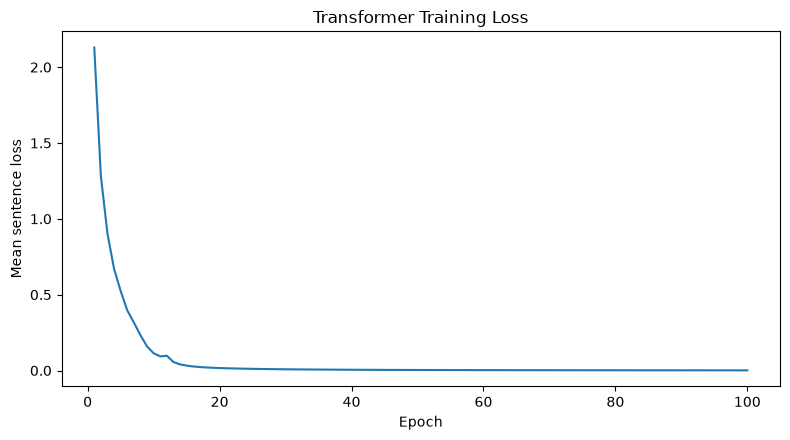

In [7]:
plt.figure(figsize=(8, 4.5))
plt.plot(range(1, NUM_EPOCHS + 1), losses)
plt.xlabel("Epoch")
plt.ylabel("Mean sentence loss")
plt.title("Transformer Training Loss")
plt.tight_layout()
# 在显示图表前保存，方便后续在 README 中引用
curve_path = Path.cwd() / "assets" / "loss_curve.png"
curve_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(curve_path, dpi=200, bbox_inches="tight")
print(f"Loss curve saved to: {curve_path}")
plt.show()


## 8. Translate / 尝试翻译

Edit `english` below using words from the printed vocabulary. Generation selects the most likely token at each step until `<EOS>` or the length limit. Low training loss does not establish general translation ability.

修改下方英文句子，单词需在词表中。每一步贪心选择概率最高的 token，遇到结束标记或长度限制停止。训练损失低不代表具有通用翻译能力。


In [8]:
@torch.no_grad()
def translate(english):
    model.eval()
    source = torch.tensor([source_ids[word] for word in english.split()])
    encoder_output = model.encode(source)
    prefix = [BOS]

    for step in range(min(16, MAX_LENGTH)):
        target = torch.tensor(prefix)
        logits = model.decode(target, encoder_output)
        next_id = logits[-1].argmax().item()
        if next_id == EOS:
            break
        prefix.append(next_id)
    return "".join(target_words[i] for i in prefix[1:])


In [9]:
english = "there is a black dog under the chair" #@param {type:"string"}
english = english.strip().lower()
print("Available words / 可用词汇:", ", ".join(source_words))
unknown = sorted(set(english.split()) - set(source_ids))
if not english:
    print("Please enter a sentence / 请输入句子")
elif unknown:
    print("Unknown words / 词表外单词:", ", ".join(unknown))
elif len(english.split()) > MAX_LENGTH:
    print(f"Use at most {MAX_LENGTH} words / 输入不能超过 {MAX_LENGTH} 个词")
else:
    print("English:", english)
    print("中文:", translate(english))


Available words / 可用词汇: a, black, cat, chair, dog, is, on, small, table, the, there, under
English: there is a black dog under the chair
中文: 椅子下面有一只黑色狗


## Try next / 继续探索

- Change `HEADS` or `NUM_LAYERS`, then run all cells again. / 修改注意力头数或层数，再全部运行。
- Add sentence pairs and retrain to expand the vocabulary. / 增加句对，重新构建词表并训练。
- Compare translations for different combinations of known words. / 比较已有词汇不同组合的翻译。

If this helped you learn, consider starring the [GitHub repository](https://github.com/Zguoxu/tiny-transformer-from-scratch). / 如果对学习有帮助，欢迎到仓库点一个 ⭐ Star。
